# K-Nearest Neighbours

### What is the main broad idea about nearest neighbour classification?

To predict the label of a new point:
1. Find the **k** labelled points nearest to it (using a distance).
2. Let those k neighbours vote.
3. The majority label is the prediction.

It needs only two things: a way to measure distance, and the assumption that points close to each other are similar. It makes no other assumptions and needs no training. The catch: it does not explain why something happens, and it gets slow and weak with many dimensions.

#### Explain the book example
how will I vote in the next election? If you know nothing else, look at my neighbours. He lives in downtown Seattle, where his neighbours mostly vote for the Democratic candidate, so "Democratic" is a good guess for him too.

If you also know his age, income, number of kids and so on, then the neighbours who are close in all those dimensions are even better predictors. That is nearest neighbours classification.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

In [3]:
def distance(v, w):
    """Euclidean distance between two vectors"""
    return np.sqrt(sum((v_i - w_i) ** 2 for v_i, w_i in zip(v, w)))

In [4]:
def majority_vote(labels):
    """labels are ordered from nearest to farthest.
    If there is a tie, drop the farthest label and vote again."""
    vote_counts = Counter(labels)
    winner, winner_count = vote_counts.most_common(1)[0]
    num_winners = len([count for count in vote_counts.values() if count == winner_count])
    if num_winners == 1:
        return winner                        # unique winner
    return majority_vote(labels[:-1])        # tie to try again without the farthest

def knn_classify(k, labeled_points, new_point):
    """Each labeled point is a pair (point, label)"""
    by_distance = sorted(labeled_points, key=lambda point_label: distance(point_label[0], new_point))
    k_nearest_labels = [label for _, label in by_distance[:k]]
    return majority_vote(k_nearest_labels)

print(majority_vote(["G", "G", "PG", "PG", "R"]))

G


#### What fruit is this? 

A fruit seller has measured some fruits: weight (grams) and sweetness (1–10). A new fruit weighs 195 g with sweetness 7.6. Is it a mango, a guava or a lemon?

In [5]:
fruits = [([220, 8.0], "Mango"), ([250, 8.5], "Mango"), ([300, 7.5], "Mango"), ([280, 9.0], "Mango"), ([240, 7.8], "Mango"),
          ([150, 5.0], "Guava"), ([170, 5.5], "Guava"), ([185, 4.5], "Guava"), ([160, 6.0], "Guava"), ([190, 5.2], "Guava"),
          ([50, 1.5], "Lemon"),  ([60, 2.0], "Lemon"),  ([45, 1.0], "Lemon"),  ([65, 1.8], "Lemon"),  ([55, 1.2], "Lemon")]
new_fruit = [195, 7.6]

# Plain Python kNN on the raw numbers
print(r"Raw data, k=3: ", knn_classify(3, fruits, new_fruit))
nearest = sorted(fruits, key=lambda pl: distance(pl[0], new_fruit))[:3]
print("3 nearest:", [(label, round(distance(p, new_fruit), 1)) for p, label in nearest])

Raw data, k=3:  Guava
3 nearest: [('Guava', np.float64(5.5)), ('Guava', np.float64(10.5)), ('Mango', np.float64(25.0))]


It says Guava, but the fruit is very sweet (7.6), like a mango. Because weight is measured in hundreds (grams) and sweetness only from 1 to 10, the distance is almost all about weight. A 195 g fruit is closest in weight to the guavas.

## Curse of dimensionality

**The curse of dimensionality** means: as the number of dimensions (features) grows, the space becomes so huge and empty that points are no longer "near" each other. Then "nearest neighbour" stops meaning much, because the nearest point is almost as far away as an average point.

kNN depends completely on "near", so it suffers badly in high dimensions.

#### Simple everyday example 
You want to find a friend who is "close" to you:
- **1 dimension (a single lane):** lots of houses near yours, easy.
- **2 dimensions (a colony with many lanes):** now "close" must be close in both directions. Fewer houses qualify.
- **3 dimensions (a big colony of tall buildings):** close in lane, row and floor. Even fewer.
- **100 dimensions (customers described by 100 features):** to be "close", two customers must match in all 100 features. Almost nobody is close to anybody!

#### Example 1: the book's experiment, average vs nearest distance
Take random points in a d-dimensional unit cube (every coordinate between 0 and 1), and measure the distances between 10,000 random pairs, for d = 1 to 100.

In [6]:
# Plain Python (the book's functions), for a few dimensions
def random_point(dim):
    return [np.random.random() for _ in range(dim)]

def random_distances(dim, num_pairs):
    return [distance(random_point(dim), random_point(dim)) for _ in range(num_pairs)]

np.random.seed(0)
for dim in [1, 2, 10, 100]:
    d = random_distances(dim, 10_000)
    avg, mn = sum(d) / len(d), min(d)
    print(f"dim {dim:>3}: average distance = {avg:.3f}, min distance = {mn:.4f}, min/average = {mn / avg:.3f}")

dim   1: average distance = 0.337, min distance = 0.0000, min/average = 0.000
dim   2: average distance = 0.519, min distance = 0.0030, min/average = 0.006
dim  10: average distance = 1.268, min distance = 0.4899, min/average = 0.386
dim 100: average distance = 4.078, min distance = 3.1256, min/average = 0.767


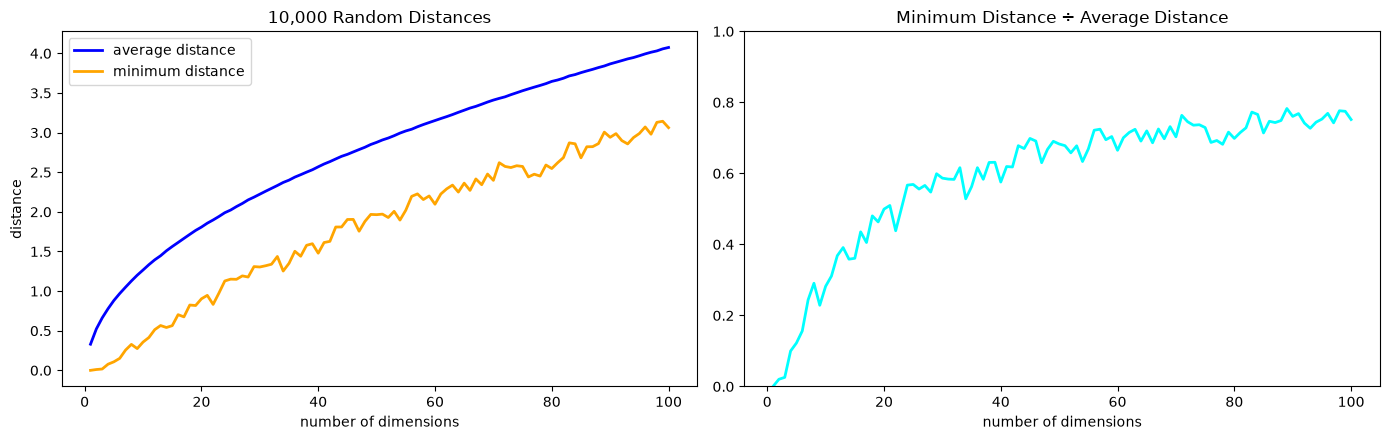

,dimension,average,minimum,min / average
0,1,0.330,0.000,0.000
1,2,0.523,0.011,0.020
4,5,0.882,0.108,0.122
9,10,1.267,0.357,0.282
49,50,2.877,1.965,0.683
99,100,4.074,3.062,0.752


In [7]:
# NumPy: all dimensions from 1 to 100, much faster
rng = np.random.default_rng(0)
dimensions = np.arange(1, 101)
avg_distances, min_distances = [], []
for dim in dimensions:
    a = rng.random((10_000, dim))
    b = rng.random((10_000, dim))
    d = np.linalg.norm(a - b, axis=1)            # 10,000 distances at once
    avg_distances.append(d.mean())
    min_distances.append(d.min())

curse = pd.DataFrame({"dimension": dimensions, "average": avg_distances, "minimum": min_distances})
curse["min / average"] = curse["minimum"] / curse["average"]

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.5))
left.plot(curse["dimension"], curse["average"], color='blue', linewidth=2, label="average distance")
left.plot(curse["dimension"], curse["minimum"], color='orange', linewidth=2, label="minimum distance")
left.set_title("10,000 Random Distances")
left.set_xlabel("number of dimensions")
left.set_ylabel("distance")
left.legend(loc="upper left")
right.plot(curse["dimension"], curse["min / average"], color='aqua', linewidth=2)
right.set_title("Minimum Distance ÷ Average Distance")
right.set_xlabel("number of dimensions")
right.set_ylim(0, 1)
plt.tight_layout()
plt.show()

curse.loc[curse["dimension"].isin([1, 2, 5, 10, 50, 100])].round(3)

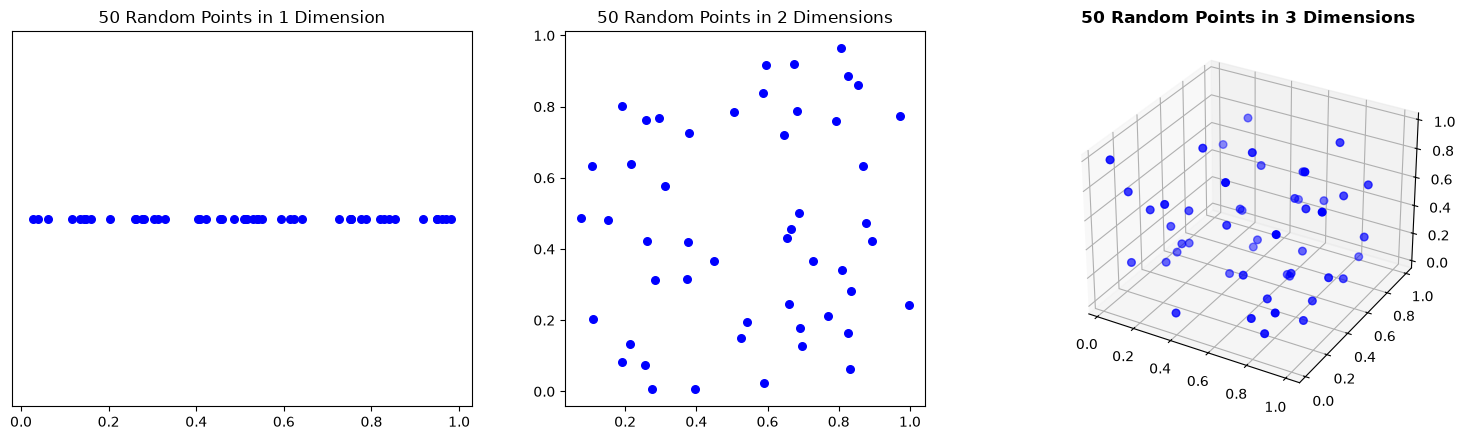

In [10]:
rng = np.random.default_rng(1)
fig = plt.figure(figsize=(15, 4.5))

ax1 = fig.add_subplot(1, 3, 1)
ax1.scatter(rng.random(50), np.zeros(50), color='blue', s=30)
ax1.set_yticks([])
ax1.set_title("50 Random Points in 1 Dimension")

ax2 = fig.add_subplot(1, 3, 2)
p2 = rng.random((50, 2))
ax2.scatter(p2[:, 0], p2[:, 1], color='blue', s=30)
ax2.set_aspect("equal")
ax2.set_title("50 Random Points in 2 Dimensions")

ax3 = fig.add_subplot(1, 3, 3, projection="3d")
p3 = rng.random((50, 3))
ax3.scatter(p3[:, 0], p3[:, 1], p3[:, 2], color='blue', s=30)
ax3.set_title("50 Random Points in 3 Dimensions", fontweight="bold")
plt.tight_layout()
plt.show()